### Домашнее задание 1

Нашел такой вот датасет: **Amazon Reviews 2018 — Prime Pantry, 5-core**.
[Ссылка](https://nijianmo.github.io/amazon/index.html).

Рекомендовать буду ещё не оценённые товары Prime Pantry. В качестве релевантности — первая будущая оценка товара **4–5**; низкие оценки не считаю положительными.

**Запуск из корня проекта, Python 3.12**
```bash
python3 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
```

In [1]:
from collections import Counter
from itertools import product
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
import gzip
import json
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from models import ItemCF, ImplicitALS, EASE, FactorizationMachine, RecencyRatingALS
from models.base import Recommender

SEED = 42
K = 10
PRIMARY_METRIC = 'NDCG@10'
TRAIN_END = pd.Timestamp('2017-01-01')
VALID_END = pd.Timestamp('2017-07-01')
DOWNLOAD_URL = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Prime_Pantry_5.json.gz'
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (11, 3.6), 'axes.grid': True, 'grid.alpha': .2})

### 1. Загрузка и описание данных
В датасете всего 137 788 отзывов.

| Поле | Смысл |
|---|---|
| reviewerID / asin | покупатель / товар |
| overall | оценка 1–5 |
| unixReviewTime | время публикации отзыва |
| reviewText / summary | текст / заголовок отзыва |
| verified | признак подтверждённой покупки |

Взаимодействие — первая наблюдаемая оценка пары «пользователь–товар». Повторные строки пары
удаляем по времени, сохраняя первую. Оценки 1–3 сохраняем
в истории, чтобы не рекомендовать уже известное; положительное обучение использует 4–5.

In [2]:
def load_raw(cache_dir='.cache/amazon_prime_pantry'):
    cache = Path(cache_dir)
    cache.mkdir(parents=True, exist_ok=True)
    path = cache / 'Prime_Pantry_5.json.gz'
    if not path.exists():
        temporary = cache / 'download.tmp'
        with urlopen(DOWNLOAD_URL, timeout=120) as response, temporary.open('wb') as target:
            while chunk := response.read(1024 * 1024):
                target.write(chunk)
        temporary.replace(path)
    with gzip.open(path, 'rt', encoding='utf-8') as stream:
        raw = pd.DataFrame(json.loads(line) for line in stream)
    return raw


def clean_data(raw):
    frame = raw.rename(columns={'reviewerID': 'user_id', 'asin': 'item_id', 'overall': 'rating'}).copy()
    audit = []
    def record(label, data):
        audit.append({'этап': label, 'события': len(data),
                      'пользователи': data.user_id.nunique(), 'товары': data.item_id.nunique()})
    record('Исходный датасет', frame)
    frame = frame.dropna(subset=['user_id', 'item_id', 'rating', 'unixReviewTime']).copy()
    frame = frame.loc[frame.rating.between(1, 5)].copy()
    frame['time'] = pd.to_datetime(frame.unixReviewTime, unit='s', utc=True).dt.tz_localize(None)
    frame['summary'] = frame.summary.fillna('')
    frame['reviewText'] = frame.reviewText.fillna('')
    frame['verified'] = frame.verified.fillna(False).astype(bool)
    record('Корректные ID, время и оценка', frame)
    frame = frame.sort_values('time', kind='stable').drop_duplicates(['user_id', 'item_id'], keep='first')
    frame = frame.reset_index(drop=True)
    record('Первая оценка каждой пары', frame)
    frame['user'], users = pd.factorize(frame.user_id, sort=True)
    frame['item'], items = pd.factorize(frame.item_id, sort=True)
    assert 100_000 <= len(frame) <= 2_000_000 and min(len(users), len(items)) >= 1000
    return frame, pd.DataFrame(audit), (len(users), len(items))


raw = load_raw()
events, cleaning_audit, shape = clean_data(raw)

In [3]:
raw[['reviewerID', 'asin', 'overall', 'summary', 'unixReviewTime']].head(3)

,reviewerID,asin,overall,summary,unixReviewTime
0,A31Y9ELLA1JUB0,B0000DIWNI,4.0,Pretty Good For plastic Wrap,1443052800
1,A2FYW9VZ0AMXKY,B0000DIWNI,5.0,"The Best Plastic Wrap for your Cooking, Baking, and Food Storage Needs",1435017600
2,A1NE43T0OM6NNX,B0000DIWNI,5.0,Good and strong.,1434153600


In [4]:
cleaning_audit

,этап,события,пользователи,товары
0,Исходный датасет,137788,14180,4970
1,"Корректные ID, время и оценка",137788,14180,4970
2,Первая оценка каждой пары,131114,14180,4970


### 2. EDA и подготовка данных
Тексты с пропусками заменяем пустой строкой, не теряя взаимодействие. Анализируем активность,
популярность, оценки, доступность текстов и подтверждённость покупок.

In [5]:
raw[['reviewerID', 'asin', 'overall', 'unixReviewTime', 'reviewText', 'summary', 'verified']].isna().sum().to_frame('пропуски')

,пропуски
reviewerID,0
asin,0
overall,0
unixReviewTime,0
reviewText,177
summary,61
verified,0


In [6]:
print('Повторных строк пары user/item:', int(raw.duplicated(['reviewerID', 'asin']).sum()))

Повторных строк пары user/item: 6674


In [7]:
activity = events.groupby('user').size()
popularity = events.groupby('item').size()
pd.concat([activity.describe(percentiles=[.5, .9, .99]).rename('оценок на пользователя'),
                   popularity.describe(percentiles=[.5, .9, .99]).rename('оценок на товар')], axis=1).round(2)

,оценок на пользователя,оценок на товар
count,14180.00,4970.00
mean,9.25,26.38
std,8.34,38.52
min,1.00,1.00
50%,7.00,13.00
90%,16.00,58.00
99%,43.00,208.31
max,183.00,575.00


Разреженность: 99.81%; доля оценок 4–5: 88.34%


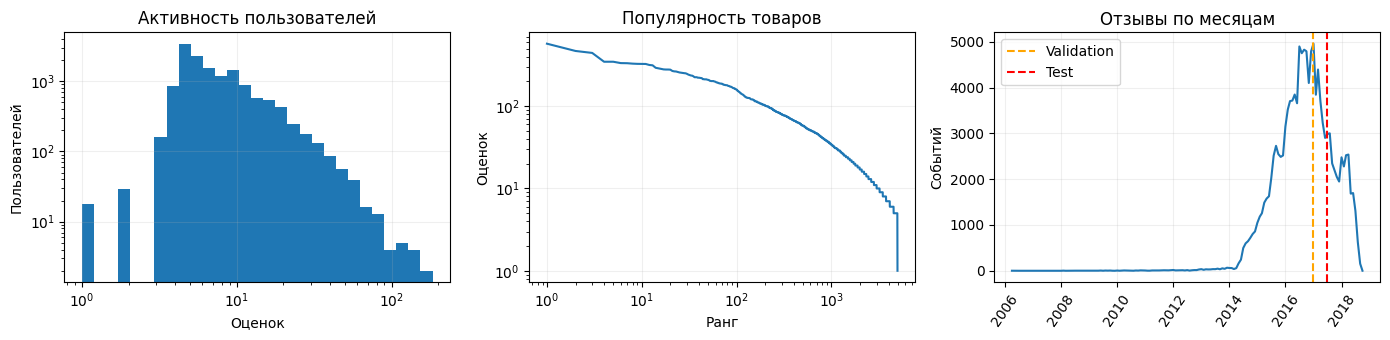

In [8]:
sparsity = 1 - len(events) / (shape[0] * shape[1])
print(f'Разреженность: {sparsity:.2%}; доля оценок 4–5: {events.rating.ge(4).mean():.2%}')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(activity, bins=np.geomspace(1, activity.max() + 1, 30))
axes[0].set(xscale='log', yscale='log', title='Активность пользователей', xlabel='Оценок', ylabel='Пользователей')
axes[1].plot(np.arange(1, len(popularity) + 1), np.sort(popularity)[::-1])
axes[1].set(xscale='log', yscale='log', title='Популярность товаров', xlabel='Ранг', ylabel='Оценок')
monthly = events.set_index('time').resample('MS').size()
axes[2].plot(monthly.index, monthly.values)
axes[2].axvline(TRAIN_END, color='orange', linestyle='--', label='Validation')
axes[2].axvline(VALID_END, color='red', linestyle='--', label='Test')
axes[2].set(title='Отзывы по месяцам', ylabel='Событий')
axes[2].tick_params(axis='x', rotation=55)
axes[2].legend()
plt.tight_layout()
plt.show()

In [9]:
def temporal_split(events):
    train = events.loc[events.time < TRAIN_END].copy()
    valid = events.loc[(events.time >= TRAIN_END) & (events.time < VALID_END)].copy()
    test = events.loc[events.time >= VALID_END].copy()
    return train, valid, test


def build_matrices(history, shape):
    positive = history.loc[history.rating >= 4].sort_values(['user', 'item'])
    rows, cols = positive.user.to_numpy(), positive.item.to_numpy()
    counts = sparse.csr_matrix((np.ones(len(positive)), (rows, cols)), shape=shape)
    last = sparse.csr_matrix((positive.time.astype('int64').to_numpy() / 1e9, (rows, cols)), shape=shape)
    ratings = sparse.csr_matrix((positive.rating.to_numpy(), (rows, cols)), shape=shape)
    seen = sparse.csr_matrix((np.ones(len(history)), (history.user, history.item)), shape=shape)
    return {'counts': counts, 'last': last, 'ratings': ratings, 'seen': seen}


def normalize_rows(matrix):
    matrix = sparse.csr_matrix(matrix, dtype=np.float64)
    norms = np.sqrt(np.asarray(matrix.multiply(matrix).sum(axis=1)).ravel())
    return sparse.diags(np.divide(1, norms, out=np.zeros_like(norms), where=norms > 0)) @ matrix

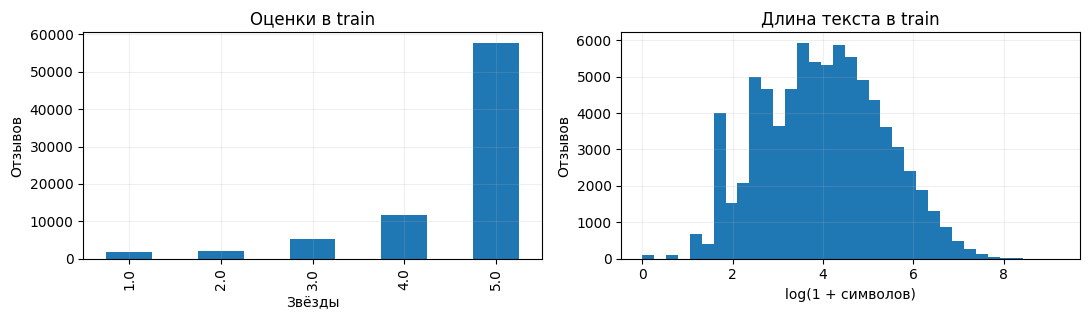

In [10]:
def make_features(history, shape, metadata=True, max_tokens=256, min_token_items=3):
    n_users, n_items = shape
    n_ids = n_users + n_items
    if not metadata:
        return (sparse.csr_matrix((np.ones(n_users), (np.arange(n_users), np.arange(n_users))), shape=(n_users, n_ids)),
                sparse.csr_matrix((np.ones(n_items), (np.arange(n_items), n_users + np.arange(n_items))), shape=(n_items, n_ids)),
                {'features': n_ids, 'tokens': []})
    documents = history.assign(text=history.summary + ' ' + history.reviewText).groupby('item', sort=True).text.agg(' '.join)
    stopwords = {'the', 'and', 'for', 'with', 'this', 'that', 'was', 'are', 'have', 'has', 'they',
                 'you', 'your', 'but', 'from', 'not', 'had', 'its', 'these', 'would', 'will', 'can', 'one'}
    counts = {int(item): Counter(word for word in re.findall(r'[a-z]{3,}', text.lower()) if word not in stopwords)
              for item, text in documents.items()}
    doc_counts = Counter(word for words in counts.values() for word in words)
    vocabulary = sorted((word for word, count in doc_counts.items() if count >= min_token_items),
                        key=lambda word: (-doc_counts[word], word))[:max_tokens]
    token_to_id = {token: index for index, token in enumerate(vocabulary)}
    rows, cols, values = [], [], []
    for item, words in counts.items():
        for word, frequency in words.items():
            if word in token_to_id:
                rows.append(item)
                cols.append(token_to_id[word])
                values.append(np.log1p(frequency) * (np.log((1 + len(documents)) / (1 + doc_counts[word])) + 1))
    text = normalize_rows(sparse.csr_matrix((values, (rows, cols)), shape=(n_items, len(vocabulary))))
    profiles = history.groupby('user').agg(mean_rating=('rating', 'mean'), verified_share=('verified', 'mean'))
    dimension = n_ids + 9 + 5 + len(vocabulary)
    ur, uc, uv = list(range(n_users)), list(range(n_users)), [1.] * n_users
    for user, row in profiles.iterrows():
        rating_bin = min(8, int((row.mean_rating - 1) * 2))
        verified_bin = int(np.searchsorted([.25, .5, .75, 1.], row.verified_share, side='left'))
        ur.extend([int(user), int(user)])
        uc.extend([n_ids + rating_bin, n_ids + 9 + verified_bin])
        uv.extend([1., 1.])
    ir, ic, iv = list(range(n_items)), list(n_users + np.arange(n_items)), [1.] * n_items
    coo = text.tocoo()
    ir.extend(coo.row.tolist())
    ic.extend((n_ids + 14 + coo.col).tolist())
    iv.extend(coo.data.tolist())
    return (sparse.csr_matrix((uv, (ur, uc)), shape=(n_users, dimension)),
            sparse.csr_matrix((iv, (ir, ic)), shape=(n_items, dimension)),
            {'features': dimension, 'tokens': vocabulary, 'items_with_reviews': len(documents)})


train, validation, test = temporal_split(events)
matrices_train = build_matrices(train, shape)
features_train = make_features(train, shape, metadata=True)
ids_train = make_features(train, shape, metadata=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
train.rating.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title='Оценки в train', xlabel='Звёзды', ylabel='Отзывов')
axes[1].hist(np.log1p(train.reviewText.str.len()), bins=35)
axes[1].set(title='Длина текста в train', xlabel='log(1 + символов)', ylabel='Отзывов')
plt.tight_layout()
plt.show()

In [11]:
print('признаков FM: ', features_train[2]['features'])
print('слов в словаре: ', len(features_train[2]['tokens']))
print('доля verified в train: ', train.verified.mean())
print('медианная длина текста train: ', train.reviewText.str.len().median())

признаков FM:  19420
слов в словаре:  256
доля verified в train:  0.829701073071027
медианная длина текста train:  54.0


**Наблюдения.** Матрица разрежена, оценки преимущественно положительные, активность неравномерна.

- Train — до **01.01.2017**, validation — **[01.01.2017, 01.07.2017)**, test — с **01.07.2017** до конца данных.
- После выбора параметров переобучаемся на train + validation. Тексты, словарь, IDF и профили
  строятся заново на доступной истории; test-оценки и тексты в признаки не попадают.
- Кандидаты — все товары хотя бы с одной положительной оценкой в обучающей истории.
  Из top-10 исключаем **все** ранее оценённые пользователем товары, включая оценки 1–3.
- Релевантны будущие оценки 4–5, только по warm товарам. Пользователь включается при наличии
  положительной обучающей истории и хотя бы одного релевантного товара. Cold случаи считаем отдельно.

Основная метрика — NDCG@10, также считаем Recall@10, HitRate@10 и долю каталога, попавшую в выдачи (Coverage@10).

In [12]:
def user_metrics(top, relevant, k):
    hit_mask = np.isin(top, list(relevant)).astype(float)
    discounts = 1 / np.log2(np.arange(2, k + 2))
    hits = float(hit_mask.sum())
    ideal = discounts[:min(k, len(relevant))].sum()
    return {f"Recall@{k}": hits / len(relevant), f"Precision@{k}": hits / k,
            f"NDCG@{k}": float(hit_mask @ discounts[:len(top)] / ideal),
            f"HR@{k}": float(hits > 0)}

In [13]:
def make_protocol(matrices, holdout):
    counts, seen = matrices['counts'], matrices['seen']
    candidates = np.asarray(counts.sum(axis=0)).ravel() > 0
    warm_users = np.asarray(counts.sum(axis=1)).ravel() > 0
    pairs = holdout.loc[holdout.rating >= 4, ['user', 'item']].drop_duplicates().copy()
    cold_user = ~warm_users[pairs.user.to_numpy()]
    cold_item = ~candidates[pairs.item.to_numpy()]
    known = np.asarray(seen[pairs.user.to_numpy(), pairs.item.to_numpy()]).ravel() > 0
    eligible = ~cold_user & ~cold_item & ~known
    relevant = {int(user): group.item.to_numpy(dtype=np.int32)
                for user, group in pairs.loc[eligible].groupby('user', sort=True)}
    users = np.array(sorted(relevant), dtype=np.int64)
    report = {'holdout_positive_pairs': len(pairs), 'cold_user_pairs': int(cold_user.sum()),
              'cold_item_pairs': int(cold_item.sum()), 'known_pairs': int(known.sum()),
              'eligible_pairs': int(eligible.sum()), 'evaluated_users': len(users),
              'warm_catalog': int(candidates.sum()), 'holdout_users': int(holdout.user.nunique())}
    return {'users': users, 'relevant': relevant, 'candidates': candidates, 'seen': seen, 'report': report}


def evaluate(model, protocol, k=10):
    recommendations = model.recommend(protocol['users'], protocol['seen'], protocol['candidates'], k=k)
    rows = []
    for user, top in zip(protocol['users'], recommendations):
        metric = user_metrics(top, protocol['relevant'][int(user)], k)
        rows.append({'user': int(user), 'NDCG@10': metric['NDCG@10'],
                     'Recall@10': metric['Recall@10'], 'HitRate@10': metric['HR@10']})
    per_user = pd.DataFrame(rows)
    metrics = per_user.drop(columns='user').mean().to_dict()
    metrics['Coverage@10'] = len(np.unique(recommendations)) / protocol['candidates'].sum()
    return metrics, per_user, recommendations


valid_protocol = make_protocol(matrices_train, validation)

In [14]:
pd.DataFrame([{'часть': name, 'события': len(part), 'пользователи': part.user.nunique(),
                       'товары': part.item.nunique(), 'от': str(part.time.min()), 'до': str(part.time.max())}
                      for name, part in [('train', train), ('validation', validation), ('test', test)]])

,часть,события,пользователи,товары,от,до
0,train,78280,9910,4795,2006-04-09 00:00:00,2016-12-31 00:00:00
1,validation,23026,4669,3907,2017-01-01 00:00:00,2017-06-30 00:00:00
2,test,29808,5433,3931,2017-07-01 00:00:00,2018-10-04 00:00:00


In [15]:
pd.Series(valid_protocol['report']).to_frame('validation')

,validation
holdout_positive_pairs,20470
cold_user_pairs,11919
cold_item_pairs,618
known_pairs,0
eligible_pairs,8248
evaluated_users,2288
warm_catalog,4751
holdout_users,4669


### 4. Подбор гиперпараметров

**Item-CF.** Сходство считаем по бинарной истории оценок 4–5, без центрирования.
Для соседства достаточно одного общего пользователя; слабые пересечения подавляет shrinkage.

**iALS.** Confidence задаём как $c_{ui}=1+\alpha\log(1+n_{ui})$.
После удаления повторов $n_{ui}\in\{0,1\}$, поэтому все положительные пары имеют одинаковый
confidence $1+\alpha\log 2$, остальные — 1.

**FM.** Используем общий bias и pointwise logistic loss с $L_2$-штрафом:
$$L=\frac1N\sum_{ui}\left[\log(1+e^{f_{ui}})-y_{ui}f_{ui}\right]
+\frac\lambda2\left(\|w\|^2+\|V\|_F^2\right).$$
На каждую положительную пару один раз выбираем две случайные неположительные пары
из обучающего каталога. Выборка фиксируется seed и используется во всех эпохах.

Метапризнаки товара — L2-нормированный TF-IDF 256 слов из прошлых текстов и заголовков отзывов.
Метапризнаки пользователя — интервалы среднего рейтинга и доли подтверждённых покупок (`verified`).
Тексты, IDF и профили пересчитываем только по истории, доступной на границе обучения.

**Custom iALS.** Заменяем сам таргет предпочтения; confidence, факторы, регуляризация, эпохи
и seed совпадают с выбранной базовой iALS. Для оценки $v_{ui}\in\{4,5\}$ во время $t_{ui}$,
границы обучения $T$, полураспада $h$ дней и нижнего уровня $a$:
$$r_{ui}=2^{-(T-t_{ui})/(86400h)},\qquad e_{ui}=(v_{ui}-3)/2,$$
$$p^*_{ui}=\mathbf1[n_{ui}>0]\left\{a+(1-a)\left[0.7r_{ui}+0.3e_{ui}\right]\right\}.$$
Недавняя оценка получает больший таргет, пять звёзд — больше четырёх. Параметры
$h$ и $a$ подбираем на validation. При $a=1$ получаем базовый таргет.
Для оценки качества сохраняем общую бинарную релевантность 4–5.

### Пространство поиска
| Модель | Перебор | Фиксировано |
|---|---|---|
| Item-CF | соседи: 40, 100; shrinkage: 10, 50 | бинарная история |
| iALS | факторы: 16, 32; λ: 1, 10 | α=20, 12 эпох |
| EASE | λ: 10, 100, 500 | бинарная история |
| FM | факторы: 16, 32; λ: 0.00001, 0.0001 | lr=0.01, 8 эпох, batch=4096, 2 negatives |
| Custom iALS | h: 90, 365 дней; a: 0.25, 0.75 | остальные параметры — выбранная базовая iALS |

Seed 42. Выбираем максимум validation NDCG@10; при равенстве — первый заданный вариант.

In [16]:
class Popularity(Recommender):
    def fit(self, counts):
        self.popularity = np.asarray((counts > 0).sum(axis=0)).ravel().astype(float)
        return self
    def score(self, users):
        return np.broadcast_to(self.popularity, (len(users), len(self.popularity))).copy()


def parameter_grid(**space):
    return [dict(zip(space, values)) for values in product(*space.values())]


def fit_model(name, params, matrices, cutoff, features, ids):
    counts = matrices['counts']
    if name == 'ItemCF': return ItemCF(**params).fit(counts)
    if name == 'iALS': return ImplicitALS(**params).fit(counts)
    if name == 'EASE': return EASE(**params).fit(counts)
    if name == 'Custom iALS':
        return RecencyRatingALS(**params).fit(counts, matrices['last'], matrices['ratings'], cutoff.timestamp())
    if name in {'FM + metadata', 'FM IDs'}:
        chosen = features if name == 'FM + metadata' else ids
        return FactorizationMachine(**params).fit(counts, chosen[0], chosen[1])
    if name == 'Popularity': return Popularity().fit(counts)
    raise ValueError(name)


def tune_model(name, configurations):
    rows = []
    for params in configurations:
        started = perf_counter()
        model = fit_model(name, params, matrices_train, TRAIN_END, features_train, ids_train)
        fit_seconds = perf_counter() - started
        metrics, _, _ = evaluate(model, valid_protocol)
        rows.append({'model': name, 'params': json.dumps(params, sort_keys=True), **metrics, 'fit_seconds': fit_seconds})
        print(f"{name}: val NDCG@10={metrics['NDCG@10']:.5f}; fit={fit_seconds:.1f}s; {params}", flush=True)
    table = pd.DataFrame(rows).sort_values(PRIMARY_METRIC, ascending=False, kind='stable').reset_index(drop=True)
    return json.loads(table.iloc[0]['params']), table


search_spaces = {
    'ItemCF': parameter_grid(neighbors=[40, 100], shrinkage=[10., 50.]),
    'iALS': parameter_grid(factors=[16, 32], regularization=[1., 10.], alpha=[20.], epochs=[12], seed=[SEED]),
    'EASE': parameter_grid(regularization=[10., 100., 500.]),
    'FM + metadata': parameter_grid(factors=[16, 32], regularization=[1e-5, 1e-4], learning_rate=[.01],
                                   epochs=[8], batch_size=[4096], negative_ratio=[2], seed=[SEED]),
}
selected, search_tables = {}, []
for name, grid in search_spaces.items():
    selected[name], table = tune_model(name, grid)
    search_tables.append(table)
search_spaces['Custom iALS'] = [dict(selected['iALS'], half_life=h, floor=a)
                               for h in [90., 365.] for a in [.25, .75]]
selected['Custom iALS'], table = tune_model('Custom iALS', search_spaces['Custom iALS'])
search_tables.append(table)
selected['FM IDs'] = dict(selected['FM + metadata'])
_, table = tune_model('FM IDs', [selected['FM IDs']])
search_tables.append(table)
validation_results = pd.concat(search_tables, ignore_index=True)
display(validation_results[['model', 'NDCG@10', 'Recall@10', 'params', 'fit_seconds']].round(5))

ItemCF: val NDCG@10=0.01723; fit=3.6s; {'neighbors': 40, 'shrinkage': 10.0}
ItemCF: val NDCG@10=0.01684; fit=2.2s; {'neighbors': 40, 'shrinkage': 50.0}
ItemCF: val NDCG@10=0.01759; fit=1.4s; {'neighbors': 100, 'shrinkage': 10.0}
ItemCF: val NDCG@10=0.01726; fit=1.3s; {'neighbors': 100, 'shrinkage': 50.0}
iALS: val NDCG@10=0.01395; fit=3.7s; {'factors': 16, 'regularization': 1.0, 'alpha': 20.0, 'epochs': 12, 'seed': 42}
iALS: val NDCG@10=0.01381; fit=3.7s; {'factors': 16, 'regularization': 10.0, 'alpha': 20.0, 'epochs': 12, 'seed': 42}
iALS: val NDCG@10=0.01504; fit=5.9s; {'factors': 32, 'regularization': 1.0, 'alpha': 20.0, 'epochs': 12, 'seed': 42}
iALS: val NDCG@10=0.01572; fit=5.9s; {'factors': 32, 'regularization': 10.0, 'alpha': 20.0, 'epochs': 12, 'seed': 42}
EASE: val NDCG@10=0.01558; fit=2.1s; {'regularization': 10.0}
EASE: val NDCG@10=0.01741; fit=1.8s; {'regularization': 100.0}
EASE: val NDCG@10=0.01798; fit=2.0s; {'regularization': 500.0}
FM + metadata: val NDCG@10=0.01300; 

,model,NDCG@10,Recall@10,params,fit_seconds
0,ItemCF,0.01759,0.02285,"{""neighbors"": 100, ""shrinkage"": 10.0}",1.44613
1,ItemCF,0.01726,0.02137,"{""neighbors"": 100, ""shrinkage"": 50.0}",1.30689
2,ItemCF,0.01723,0.02267,"{""neighbors"": 40, ""shrinkage"": 10.0}",3.60453
3,ItemCF,0.01684,0.02184,"{""neighbors"": 40, ""shrinkage"": 50.0}",2.24416
4,iALS,0.01572,0.02133,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 32, ""regularization"": 10.0, ""seed"": 42}",5.91437
5,iALS,0.01504,0.02002,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 32, ""regularization"": 1.0, ""seed"": 42}",5.85064
6,iALS,0.01395,0.01960,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 16, ""regularization"": 1.0, ""seed"": 42}",3.68067
7,iALS,0.01381,0.01914,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 16, ""regularization"": 10.0, ""seed"": 42}",3.67375
8,EASE,0.01798,0.02288,"{""regularization"": 500.0}",1.96374
9,EASE,0.01741,0.02300,"{""regularization"": 100.0}",1.79791


In [17]:
frozen = json.loads(json.dumps({'seed': SEED, 'primary_metric': PRIMARY_METRIC,
    'train_end': str(TRAIN_END), 'valid_end': str(VALID_END),
    'models': selected, 'search_spaces': search_spaces}))
validation_best = validation_results.sort_values(PRIMARY_METRIC, ascending=False, kind='stable').drop_duplicates('model')

In [18]:
validation_best[['model', 'NDCG@10', 'Recall@10', 'params']].reset_index(drop=True).round(5)

,model,NDCG@10,Recall@10,params
0,EASE,0.01798,0.02288,"{""regularization"": 500.0}"
1,ItemCF,0.01759,0.02285,"{""neighbors"": 100, ""shrinkage"": 10.0}"
2,Custom iALS,0.01657,0.02372,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 32, ""floor"": 0.25, ""half_life"": 90.0, ""regularization"": 10.0, ""seed"": 42}"
3,FM IDs,0.01620,0.02220,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 0.0001, ""seed"": 42}"
4,iALS,0.01572,0.02133,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 32, ""regularization"": 10.0, ""seed"": 42}"
5,FM + metadata,0.01510,0.01976,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 0.0001, ""seed"": 42}"


In [20]:
best_on_validation = validation_best.loc[validation_best.model.isin(search_spaces)].iloc[0]['model']
print('Лидер validation среди пяти моделей:', best_on_validation)

Лидер validation среди пяти моделей: EASE


### 5. Финальное сравнение на test
История теперь train + validation. Заново строим текстовые признаки, IDF, пользовательские профили и
таргет давности на 01.07.2017.

In [22]:
history_final = pd.concat([train, validation], ignore_index=True)
matrices_final = build_matrices(history_final, shape)
features_final = make_features(history_final, shape, metadata=True)
ids_final = make_features(history_final, shape, metadata=False)
test_protocol = make_protocol(matrices_final, test)
display(pd.DataFrame({'validation': valid_protocol['report'], 'test': test_protocol['report']}))
final_models, test_details, test_recommendations = {}, {}, {}
test_rows = []
for name in [*selected, 'Popularity']:
    params = frozen['models'].get(name, {})
    started = perf_counter()
    model = fit_model(name, params, matrices_final, VALID_END, features_final, ids_final)
    fit_seconds = perf_counter() - started
    started = perf_counter()
    metrics, per_user, recommendations = evaluate(model, test_protocol)
    predict_seconds = perf_counter() - started
    final_models[name], test_details[name], test_recommendations[name] = model, per_user, recommendations
    test_rows.append({'model': name, **metrics, 'fit_seconds': fit_seconds,
                      'recommend_seconds': predict_seconds, 'params': json.dumps(params, sort_keys=True)})
    print(f"{name}: test NDCG@10={metrics['NDCG@10']:.5f}; fit={fit_seconds:.1f}s", flush=True)
test_results = pd.DataFrame(test_rows).sort_values(PRIMARY_METRIC, ascending=False, kind='stable').reset_index(drop=True)
display(test_results.round(3))

,validation,test
holdout_positive_pairs,20470,26091
cold_user_pairs,11919,15355
cold_item_pairs,618,226
known_pairs,0,0
eligible_pairs,8248,10625
evaluated_users,2288,2884
warm_catalog,4751,4933
holdout_users,4669,5433


ItemCF: test NDCG@10=0.01912; fit=2.1s
iALS: test NDCG@10=0.01560; fit=5.9s
EASE: test NDCG@10=0.01855; fit=1.8s
FM + metadata: test NDCG@10=0.01380; fit=16.8s
Custom iALS: test NDCG@10=0.01641; fit=6.2s
FM IDs: test NDCG@10=0.01490; fit=9.0s
Popularity: test NDCG@10=0.01454; fit=0.0s


,model,NDCG@10,Recall@10,HitRate@10,Coverage@10,fit_seconds,recommend_seconds,params
0,ItemCF,0.019,0.025,0.075,0.787,2.129,0.677,"{""neighbors"": 100, ""shrinkage"": 10.0}"
1,EASE,0.019,0.023,0.077,0.508,1.812,3.347,"{""regularization"": 500.0}"
2,Custom iALS,0.016,0.021,0.072,0.130,6.247,1.946,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 32, ""floor"": 0.25, ""half_life"": 90.0, ""regularization"": 10.0, ""seed"": 42}"
3,iALS,0.016,0.019,0.068,0.135,5.941,1.790,"{""alpha"": 20.0, ""epochs"": 12, ""factors"": 32, ""regularization"": 10.0, ""seed"": 42}"
4,FM IDs,0.015,0.021,0.074,0.003,8.989,1.721,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 0.0001, ""seed"": 42}"
5,Popularity,0.015,0.020,0.070,0.003,0.002,1.022,{}
6,FM + metadata,0.014,0.021,0.070,0.006,16.794,1.735,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.01, ""negative_ratio"": 2, ""regularization"": 0.0001, ""seed"": 42}"


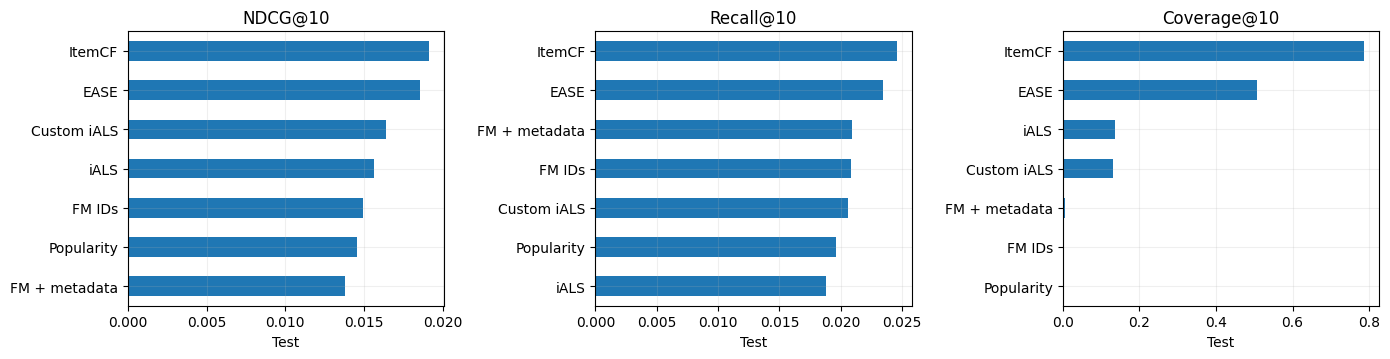

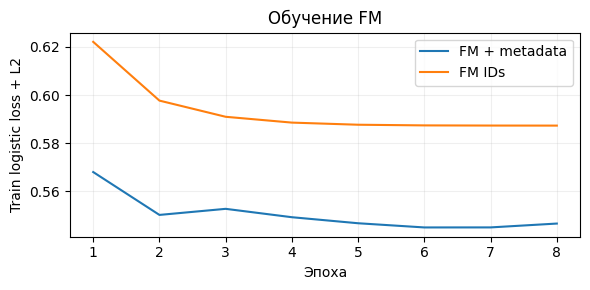

In [27]:
comparison = test_results.set_index('model')
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10', 'Coverage@10']):
    comparison[metric].sort_values().plot.barh(ax=ax)
    ax.set(title=metric, xlabel='Test', ylabel='')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3))
for name in ['FM + metadata', 'FM IDs']:
    ax.plot(np.arange(1, len(final_models[name].losses_) + 1), final_models[name].losses_, label=name)
ax.set(xlabel='Эпоха', ylabel='Train logistic loss + L2', title='Обучение FM')
ax.legend()
plt.tight_layout()
plt.show()

### Пример рекомендаций

In [25]:
example_user = int(test_protocol['users'][0])
known = history_final.sort_values('time', kind='stable').drop_duplicates('item', keep='last').set_index('item')
display(history_final.loc[history_final.user.eq(example_user), ['time', 'item_id', 'rating', 'summary']].tail(5))
example = []
for name in search_spaces:
    for rank, item in enumerate(test_recommendations[name][0], start=1):
        example.append({'model': name, 'rank': rank, 'ASIN': known.loc[item, 'item_id'],
                        'прошлый отзыв': known.loc[item, 'summary'][:70],
                        'попадание': int(item in test_protocol['relevant'][example_user])})
display(pd.DataFrame(example))

,time,item_id,rating,summary
77809,2016-12-28,B01H362CRC,5.0,Five Stars


,model,rank,ASIN,прошлый отзыв,попадание
0,ItemCF,1,B00VTU7B3E,Soft enough to smudge yet stays on!,0
1,ItemCF,2,B01782IN10,Four Stars,0
2,ItemCF,3,B016F7C3UQ,Five Stars,0
3,ItemCF,4,B01C6Y7RFS,softly no sneezes,0
4,ItemCF,5,B00WFVWETM,Four Stars,0
5,ItemCF,6,B01CTZCKKQ,Legit Swiffer wet mop refills,0
6,ItemCF,7,B00MY2T0BM,"Works well, more comfortable than the other products",0
7,ItemCF,8,B017XKS40M,Five Stars,0
8,ItemCF,9,B00I8G6XBS,I always use this peanut butter because of the texture ...,0
9,ItemCF,10,B00UOLCK4E,Good product,0


### 6. Выводы

1. Лидер validation — EASE. На test лучший из пяти — ItemCF: NDCG@10=0.01912, Recall@10=0.02453; настройки {"neighbors": 100, "shrinkage": 10.0}.

2. FM + metadata vs. FM IDs: diff NDCG@10=-0.00110 (-7.4%).

3. Custom iALS vs. iALS: diff NDCG@10=+0.00081 (+5.2%).

4. Ограничения: один split/seed, небольшой поиск...